In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("eda_sales_data.csv")

df.head()

,order_id,region,product,category,quantity,price,sales
0,1,North,Laptop,Electronics,2.0,800.0,1600.0
1,2,South,Mouse,Accessories,5.0,20.0,100.0
2,3,East,Keyboard,Accessories,3.0,50.0,150.0
3,4,West,Monitor,Electronics,2.0,300.0,600.0
4,5,North,Laptop,Electronics,4.0,800.0,3200.0


In [3]:
df.shape

(21, 7)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  21 non-null     int64  
 1   region    21 non-null     object 
 2   product   21 non-null     object 
 3   category  21 non-null     object 
 4   quantity  20 non-null     float64
 5   price     20 non-null     float64
 6   sales     20 non-null     float64
dtypes: float64(3), int64(1), object(3)
memory usage: 1.3+ KB


In [5]:
df.isnull().sum()

order_id    0
region      0
product     0
category    0
quantity    1
price       1
sales       1
dtype: int64

In [6]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_summary

,Missing Values,Missing Percentage
order_id,0,0.00
region,0,0.00
product,0,0.00
category,0,0.00
quantity,1,4.76
price,1,4.76
sales,1,4.76


In [7]:
df.duplicated().sum()

1

In [8]:
df[df.duplicated()]

,order_id,region,product,category,quantity,price,sales
20,5,North,Laptop,Electronics,4.0,800.0,3200.0


In [9]:
df.isnull().sum()

order_id    0
region      0
product     0
category    0
quantity    1
price       1
sales       1
dtype: int64

In [10]:
df_mean = df.copy()

df_mean["quantity"] = df_mean["quantity"].fillna(
    df_mean["quantity"].mean()
)

df_mean["quantity"].isnull().sum()

0

In [11]:
df["quantity"].mean()

5.1

In [12]:
df_median = df.copy()

df_median["price"] = df_median["price"].fillna(
    df_median["price"].median()
)

df_median["price"].isnull().sum()

0

In [13]:
df["price"].median()

60.0

In [14]:
df_mode = df.copy()

df_mode["region"] = df_mode["region"].fillna(
    df_mode["region"].mode()[0]
)

df_mode["region"].isnull().sum()

0

In [15]:
df_ffill = df.copy()

df_ffill["sales"] = df_ffill["sales"].ffill()

df_ffill["sales"].isnull().sum()

0

In [16]:
df_ffill[["order_id", "sales"]]

,order_id,sales
0,1,1600.0
1,2,100.0
2,3,150.0
3,4,600.0
4,5,3200.0
5,6,160.0
6,7,300.0
7,8,900.0
8,9,420.0
9,10,800.0


In [17]:
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    return outliers, lower_bound, upper_bound

In [18]:
outliers_quantity, lower_q, upper_q = detect_outliers_iqr(df, "quantity")

print("Lower bound:", lower_q)
print("Upper bound:", upper_q)
print("Number of outliers:", len(outliers_quantity))

outliers_quantity

Lower bound: -3.0
Upper bound: 13.0
Number of outliers: 0


,order_id,region,product,category,quantity,price,sales


In [19]:
outliers_price, lower_p, upper_p = detect_outliers_iqr(df, "price")

print("Lower bound:", lower_p)
print("Upper bound:", upper_p)
print("Number of outliers:", len(outliers_price))

outliers_price

Lower bound: -1075.0
Upper bound: 1925.0
Number of outliers: 0


,order_id,region,product,category,quantity,price,sales


In [20]:
outliers_sales, lower_s, upper_s = detect_outliers_iqr(df, "sales")

print("Lower bound:", lower_s)
print("Upper bound:", upper_s)
print("Number of outliers:", len(outliers_sales))

outliers_sales

Lower bound: -843.75
Upper bound: 2066.25
Number of outliers: 3


,order_id,region,product,category,quantity,price,sales
4,5,North,Laptop,Electronics,4.0,800.0,3200.0
14,15,East,Laptop,Electronics,3.0,800.0,2400.0
20,5,North,Laptop,Electronics,4.0,800.0,3200.0


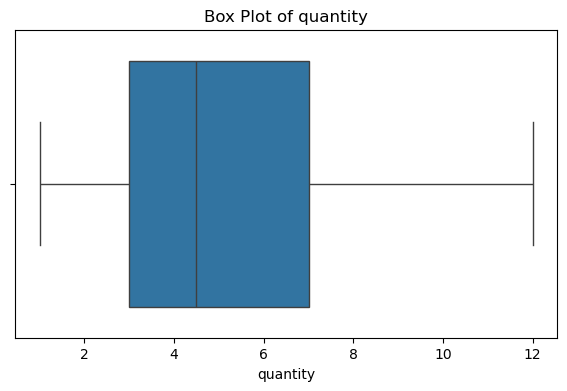

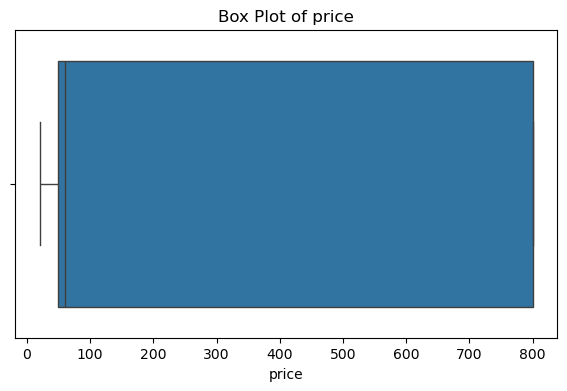

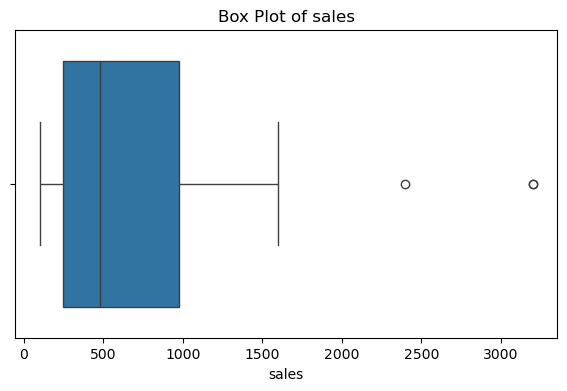

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_for_outliers = ["quantity", "price", "sales"]

for column in numeric_for_outliers:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=df[column])
    plt.title(f"Box Plot of {column}")
    plt.xlabel(column)
    plt.show()

In [25]:
df_clean = df.copy()

for column in numeric_for_outliers:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_clean[column] = df_clean[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

In [26]:
df_clean[numeric_for_outliers].describe()

,quantity,price,sales
count,20.000000,20.000000,20.000000
mean,5.100000,308.000000,748.437500
std,2.954034,342.983811,680.684383
min,1.000000,20.000000,100.000000
25%,3.000000,50.000000,247.500000
50%,4.500000,60.000000,480.000000
75%,7.000000,800.000000,975.000000
max,12.000000,800.000000,2066.250000


In [27]:
for column in ["region", "product", "category"]:
    print(f"\n{column}:")
    print(df[column].unique())


region:
['North' 'South' 'East' 'West']

product:
['Laptop' 'Mouse' 'Keyboard' 'Monitor' 'Headset']

category:
['Electronics' 'Accessories']


In [28]:
df_clean = df.copy()

In [29]:
text_columns = ["region", "product", "category"]

for column in text_columns:
    df_clean[column] = df_clean[column].str.strip()

In [30]:
for column in text_columns:
    df_clean[column] = df_clean[column].str.title()

In [31]:
for column in text_columns:
    print(f"\n{column}:")
    print(df_clean[column].unique())


region:
['North' 'South' 'East' 'West']

product:
['Laptop' 'Mouse' 'Keyboard' 'Monitor' 'Headset']

category:
['Electronics' 'Accessories']


In [32]:
df_clean["region"] = df_clean["region"].replace({
    "Noth": "North",
    "Souh": "South"
})

In [33]:
df_final = df.copy()

In [34]:
df_final["quantity"] = df_final["quantity"].fillna(
    df_final["quantity"].median()
)

df_final["price"] = df_final["price"].fillna(
    df_final["price"].median()
)

df_final["sales"] = df_final["sales"].fillna(
    df_final["sales"].median()
)

In [35]:
df_final["region"] = df_final["region"].fillna(
    df_final["region"].mode()[0]
)

In [36]:
text_columns = ["region", "product", "category"]

for column in text_columns:
    df_final[column] = df_final[column].str.strip().str.title()

In [37]:
print("Duplicates before:", df_final.duplicated().sum())

Duplicates before: 1


In [38]:
df_final = df_final.drop_duplicates()

In [39]:
print("Duplicates after:", df_final.duplicated().sum())

Duplicates after: 0


In [40]:
numeric_columns = ["quantity", "price", "sales"]

for column in numeric_columns:
    Q1 = df_final[column].quantile(0.25)
    Q3 = df_final[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_final[column] = df_final[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

In [41]:
df_final.head()

,order_id,region,product,category,quantity,price,sales
0,1,North,Laptop,Electronics,2.0,800.0,1600.00
1,2,South,Mouse,Accessories,5.0,20.0,100.00
2,3,East,Keyboard,Accessories,3.0,50.0,150.00
3,4,West,Monitor,Electronics,2.0,300.0,600.00
4,5,North,Laptop,Electronics,4.0,800.0,1691.25


In [42]:
print("Shape:", df_final.shape)
print("\nMissing values:")
print(df_final.isnull().sum())

print("\nDuplicates:", df_final.duplicated().sum())

Shape: (20, 7)

Missing values:
order_id    0
region      0
product     0
category    0
quantity    0
price       0
sales       0
dtype: int64

Duplicates: 0


In [43]:
df_final.to_csv("cleaned_eda_sales_data.csv", index=False)